### Temporal train/test split — corrected validation

This notebook fixes a known limitation of `residential.ipynb` / `commercial.ipynb`: the original R2 scores (mobile_home 0.8488, SF detached 0.9072, ..., ComStock 0.93-0.98) were measured with `train_test_split(..., shuffle default True)` on hourly data that is strongly autocorrelated. A random shuffle puts test rows right next to near-identical training rows in time (adjacent hours have almost the same weather and almost the same load), which inflates R2.

It reuses the already-downloaded raw archetype CSVs and the already-generated weather/building-count/sqft exports (no re-download, no Census API call needed).

**Two findings emerged while building this that changed the approach:**

1. A naive single chronological 80/20 holdout (train Jan-Oct, test Oct-Dec) is *itself* unreliable with only one year of data: the test tail is the only place in the whole dataset containing late-autumn/winter behavior, so several archetypes score negative R2 there regardless of whether the calendar features are ordinal or cyclically (sin/cos) encoded. The fix is not the encoding — it's the evaluation methodology.
2. A blocked 4-fold seasonal CV (train on 3 seasons, test on the held-out one, rotate) gives a far more informative and more favorable picture: commercial archetypes generalize well across seasons (R2 mostly 0.6-0.96), while residential archetypes are markedly weaker in winter/spring (sometimes near zero or negative). That is a genuine, reportable finding — plausibly because ResStock's electricity-only target conflates homes with electric heat and homes with gas heat, and the feature set can't tell them apart, whereas commercial schedule-driven loads (offices, schools) are more homogeneous year-round.

So: the **seasonal CV mean R2** (not the single holdout) is the number this notebook reports as the honest replacement for the original leaky R2. The final production models used to regenerate the bus-level profiles are then trained on the **full year** (standard practice: CV estimates generalization, the deployed model uses all available data once that estimate is trusted).

In [1]:
# env1 3.11.13 (repo default)
import pandas as pd
import numpy as np
from pathlib import Path
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

exports = Path("loadcurves/exports")
assert exports.exists(), f"Expected exports dir at {exports.resolve()}"


#### Weather (reused from cache, no re-download)

Builds two feature sets: `feature_cols_raw` (identical to the original notebooks: ordinal `hour`/`month`/`day_of_week`) and `feature_cols_cyclical` (sin/cos encoded calendar features), used below to show that encoding alone does not rescue a single fragile holdout.

In [2]:
weather = pd.read_csv(exports / "TX_PUMA_COAST_2018_weather.csv")

location_id = "G4804610"
weather_clean = weather[weather["location_id"] == location_id].copy()
weather_clean["date_time"] = pd.to_datetime(weather_clean["date_time"])
weather_clean = weather_clean.sort_values("date_time").reset_index(drop=True)

weather_clean["hour"] = weather_clean["date_time"].dt.hour
weather_clean["month"] = weather_clean["date_time"].dt.month
weather_clean["day_of_week"] = weather_clean["date_time"].dt.dayofweek

weather_clean["month_sin"] = np.sin(2 * np.pi * weather_clean["month"] / 12)
weather_clean["month_cos"] = np.cos(2 * np.pi * weather_clean["month"] / 12)
weather_clean["hour_sin"] = np.sin(2 * np.pi * weather_clean["hour"] / 24)
weather_clean["hour_cos"] = np.cos(2 * np.pi * weather_clean["hour"] / 24)
weather_clean["dow_sin"] = np.sin(2 * np.pi * weather_clean["day_of_week"] / 7)
weather_clean["dow_cos"] = np.cos(2 * np.pi * weather_clean["day_of_week"] / 7)

weather_feature_cols = [
    "Dry Bulb Temperature [\u00b0C]",
    "Relative Humidity [%]",
    "Wind Speed [m/s]",
    "Global Horizontal Radiation [W/m2]",
]

feature_cols_raw = weather_feature_cols + ["hour", "month", "day_of_week"]
feature_cols_cyclical = weather_feature_cols + [
    "hour_sin", "hour_cos", "month_sin", "month_cos", "dow_sin", "dow_cos",
]

X_raw = weather_clean[feature_cols_raw]
X_cyc = weather_clean[feature_cols_cyclical]
print(f"X_raw shape: {X_raw.shape}  |  X_cyc shape: {X_cyc.shape}")


X_raw shape: (8760, 7)  |  X_cyc shape: (8760, 10)


#### Load & normalize raw archetype profiles (residential + commercial)

Same normalization logic as the original notebooks: divide by `units_represented` (residential, kWh/home) or `floor_area_represented` (commercial, kWh/sqft). One shared function handles both since the only difference is the unit column.

In [3]:
def aggregate_to_hourly(df_15min, target_col, unit_col):
    df = df_15min.copy()
    time_col = "date_time" if "date_time" in df.columns else "timestamp"
    if time_col in df.columns:
        df[time_col] = pd.to_datetime(df[time_col])
        df = df.set_index(time_col)
    else:
        df.index = pd.date_range(start="2018-01-01 00:15:00", periods=len(df), freq="15min")

    unit_count = df[unit_col].iloc[0] if unit_col in df.columns else 1.0
    if unit_count == 0:
        unit_count = 1.0

    df_hourly = df[[target_col]].resample("h", label="right", closed="right").sum()
    if not df_hourly.empty and df_hourly.index[0].hour == 0 and df_hourly.index[0].minute == 0:
        df_hourly = df_hourly.iloc[1:]

    df_hourly[target_col] = df_hourly[target_col] / unit_count
    return df_hourly


RES_TARGET_COL = "out.electricity.total.energy_consumption..kwh"   # double dot (ResStock)
COM_TARGET_COL = "out.electricity.total.energy_consumption.kwh"    # single dot (ComStock)

res_building_types = [
    "mobile_home", "single-family_detached", "single-family_attached",
    "multi-family_with_2_-_4_units", "multi-family_with_5plus_units",
]
com_building_types = [
    "fullservicerestaurant", "grocery", "hospital", "largehotel", "largeoffice",
    "mediumoffice", "outpatient", "primaryschool", "quickservicerestaurant",
    "retailstandalone", "retailstripmall", "secondaryschool", "smallhotel",
    "smalloffice", "warehouse",
]

hourly_profiles_res = {}
for b in res_building_types:
    raw = pd.read_csv(exports / f"up00-2a-{b}.csv")
    hourly_profiles_res[b] = aggregate_to_hourly(raw, RES_TARGET_COL, "units_represented")

hourly_profiles_com = {}
for b in com_building_types:
    raw = pd.read_csv(exports / f"up0-2a-{b}.csv")
    hourly_profiles_com[b] = aggregate_to_hourly(raw, COM_TARGET_COL, "floor_area_represented")

all_profiles = {**{b: (df, RES_TARGET_COL) for b, df in hourly_profiles_res.items()},
                 **{b: (df, COM_TARGET_COL) for b, df in hourly_profiles_com.items()}}

print(f"Residential profiles loaded: {len(hourly_profiles_res)} (expect 5)")
print(f"Commercial profiles loaded:  {len(hourly_profiles_com)} (expect 15)")
for name, (d, _) in all_profiles.items():
    if len(d) != len(X_raw):
        print(f"  !! length mismatch for {name}: {len(d)} rows vs X {len(X_raw)} rows")


Residential profiles loaded: 5 (expect 5)
Commercial profiles loaded:  15 (expect 15)


#### Split strategies

In [4]:
def chronological_split(X, y, test_size=0.2):
    """Train on the first (1-test_size) of the year, test on the rest. No shuffling."""
    n = len(X)
    split_idx = int(n * (1 - test_size))
    return X.iloc[:split_idx], X.iloc[split_idx:], y[:split_idx], y[split_idx:]


SEASON_MONTHS = {
    "winter": [12, 1, 2],
    "spring": [3, 4, 5],
    "summer": [6, 7, 8],
    "fall": [9, 10, 11],
}


def seasonal_blocked_cv(X, y, months_series, n_estimators=100, max_depth=20, random_state=42):
    """Leave-one-season-out CV: train on 3 seasons, test on the held-out one. Returns per-season R2/RMSE."""
    results = {}
    months_arr = months_series.values
    for season, months in SEASON_MONTHS.items():
        test_mask = np.isin(months_arr, months)
        X_train, X_test = X[~test_mask], X[test_mask]
        y_train, y_test = y[~test_mask], y[test_mask]
        rf = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth,
                                    random_state=random_state, n_jobs=-1)
        rf.fit(X_train, y_train)
        preds = rf.predict(X_test)
        results[season] = {
            "R2": r2_score(y_test, preds),
            "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
            "n_test": int(test_mask.sum()),
        }
    return results


#### Diagnostic — does a single chronological holdout even work?

Runs the naive 80/20 chronological holdout twice: once with raw ordinal calendar features (the original encoding), once with cyclical encoding. Neither model here is saved — this is purely to check whether the holdout itself is trustworthy before deciding what to report.

In [5]:
split_idx_check = int(len(X_raw) * 0.8)
train_months = sorted(weather_clean["month"].iloc[:split_idx_check].unique())
test_months = sorted(weather_clean["month"].iloc[split_idx_check:].unique())
print(f"Train months: {train_months}")
print(f"Test months:  {test_months}")
print(f"Test months never seen in training: {sorted(set(test_months) - set(train_months))}")
print()

diagnostic_results = []
for b_type, (df_hourly, target_col) in all_profiles.items():
    y = df_hourly[target_col].values

    X_train_r, X_test_r, y_train_r, y_test_r = chronological_split(X_raw, y, test_size=0.2)
    rf_raw = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
    rf_raw.fit(X_train_r, y_train_r)
    score_raw = r2_score(y_test_r, rf_raw.predict(X_test_r))

    X_train_c, X_test_c, y_train_c, y_test_c = chronological_split(X_cyc, y, test_size=0.2)
    rf_cyc = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
    rf_cyc.fit(X_train_c, y_train_c)
    score_cyc = r2_score(y_test_c, rf_cyc.predict(X_test_c))

    diagnostic_results.append({
        "Building_Type": b_type,
        "R2_Chronological_Raw": score_raw,
        "R2_Chronological_Cyclical": score_cyc,
    })

diagnostic_df = pd.DataFrame(diagnostic_results)
print(f"Negative R2 with raw encoding:      {(diagnostic_df['R2_Chronological_Raw'] < 0).sum()} / {len(diagnostic_df)}")
print(f"Negative R2 with cyclical encoding: {(diagnostic_df['R2_Chronological_Cyclical'] < 0).sum()} / {len(diagnostic_df)}")
diagnostic_df.sort_values("R2_Chronological_Cyclical")


Train months: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10)]
Test months:  [np.int32(1), np.int32(10), np.int32(11), np.int32(12)]
Test months never seen in training: [np.int32(11), np.int32(12)]

Negative R2 with raw encoding:      9 / 20
Negative R2 with cyclical encoding: 7 / 20


,Building_Type,R2_Chronological_Raw,R2_Chronological_Cyclical
1,single-family_detached,-1.786469,-2.222763
0,mobile_home,-0.325537,-0.991436
17,smallhotel,-0.869531,-0.843679
8,largehotel,-0.829284,-0.673099
2,single-family_attached,-0.391240,-0.670509
16,secondaryschool,-0.538064,-0.504645
3,multi-family_with_2_-_4_units,-0.189413,-0.445713
18,smalloffice,0.039835,0.119007
10,mediumoffice,0.138166,0.140121
12,primaryschool,-0.290455,0.384042


**Conclusion of the diagnostic:** cyclical encoding does not reliably fix the single holdout (it helps a few archetypes, hurts others) because the deeper problem is that the test tail (Oct-Dec) is the *only* place in one year of data with that seasonal behavior — the model simply doesn't have comparable training examples, encoding or not. A single chronological split on 8760 hours of one single year is not a reliable evaluation protocol by itself. The blocked seasonal CV below is used as the actual evaluation from this point on.

#### Blocked seasonal 4-fold CV — the evaluation that is actually reported

Train on 3 seasons, test on the 4th, rotate. Every fold has 3 seasons worth of training diversity instead of a single truncated stretch, and (except for the two seasonal boundary edges) is still non-leaky: no shuffling within a season, no adjacent-hour test/train pairs.

In [6]:
seasonal_results = []

print("Running blocked seasonal CV (4 folds x 20 archetypes, cyclical features)...")
for b_type, (df_hourly, target_col) in all_profiles.items():
    y = df_hourly[target_col].values
    season_scores = seasonal_blocked_cv(X_cyc, y, weather_clean["month"])
    for season, m in season_scores.items():
        seasonal_results.append({"Building_Type": b_type, "Season": season, **m})
    print(f" -> {b_type:35s} " + "  ".join(f"{s}: R2={m['R2']:.3f}" for s, m in season_scores.items()))

seasonal_df = pd.DataFrame(seasonal_results)
metrics_temporal_dir = Path("metrics_temporal")
metrics_temporal_dir.mkdir(exist_ok=True)
seasonal_df.to_csv(metrics_temporal_dir / "seasonal_blocked_cv_metrics.csv", index=False)

seasonal_pivot = seasonal_df.pivot(index="Building_Type", columns="Season", values="R2")[["winter", "spring", "summer", "fall"]]
seasonal_pivot["mean"] = seasonal_pivot.mean(axis=1)
seasonal_pivot["std"] = seasonal_pivot[["winter", "spring", "summer", "fall"]].std(axis=1)
seasonal_pivot = seasonal_pivot.sort_values("mean", ascending=False)
seasonal_pivot


Running blocked seasonal CV (4 folds x 20 archetypes, cyclical features)...
 -> mobile_home                         winter: R2=0.054  spring: R2=0.193  summer: R2=0.862  fall: R2=0.599
 -> single-family_detached              winter: R2=0.057  spring: R2=-0.755  summer: R2=0.724  fall: R2=0.137
 -> single-family_attached              winter: R2=0.305  spring: R2=-0.282  summer: R2=0.749  fall: R2=0.603
 -> multi-family_with_2_-_4_units       winter: R2=0.345  spring: R2=0.073  summer: R2=0.825  fall: R2=0.627
 -> multi-family_with_5plus_units       winter: R2=0.677  spring: R2=0.617  summer: R2=0.913  fall: R2=0.819
 -> fullservicerestaurant               winter: R2=0.915  spring: R2=0.867  summer: R2=0.962  fall: R2=0.937
 -> grocery                             winter: R2=0.792  spring: R2=0.825  summer: R2=0.929  fall: R2=0.869
 -> hospital                            winter: R2=0.909  spring: R2=0.811  summer: R2=0.939  fall: R2=0.902
 -> largehotel                          winter: R2

Season,winter,spring,summer,fall,mean,std
Building_Type,,,,,,
fullservicerestaurant,0.915065,0.866974,0.961515,0.936686,0.920060,0.040158
quickservicerestaurant,0.901881,0.856667,0.955716,0.926506,0.910193,0.041923
retailstripmall,0.892292,0.857045,0.960205,0.899630,0.902293,0.042850
outpatient,0.905141,0.773017,0.955172,0.939449,0.893195,0.082797
hospital,0.909361,0.810838,0.938502,0.901967,0.890167,0.055188
retailstandalone,0.835562,0.825091,0.950543,0.902080,0.878319,0.058998
smalloffice,0.836848,0.821188,0.918408,0.859299,0.858936,0.042622
secondaryschool,0.833727,0.834486,0.931372,0.819439,0.854756,0.051544
grocery,0.792401,0.825126,0.928759,0.869021,0.853827,0.058999


#### Headline comparison: original random-split R2 vs seasonal-CV-mean R2

This is the number that should replace the original R2 table in the paper.

                Building_Type      Sector  R2_Random_Split  R2_Seasonal_CV_Mean  Drop_vs_Random
        fullservicerestaurant  Commercial         0.981995             0.920060        0.061935
       quickservicerestaurant  Commercial         0.977317             0.910193        0.067124
              retailstripmall  Commercial         0.978708             0.902293        0.076415
                   outpatient  Commercial         0.978327             0.893195        0.085132
                     hospital  Commercial         0.972146             0.890167        0.081979
             retailstandalone  Commercial         0.974164             0.878319        0.095845
                  smalloffice  Commercial         0.973450             0.858936        0.114514
              secondaryschool  Commercial         0.968221             0.854756        0.113465
                      grocery  Commercial         0.965787             0.853827        0.111961
                    warehouse  Commercia

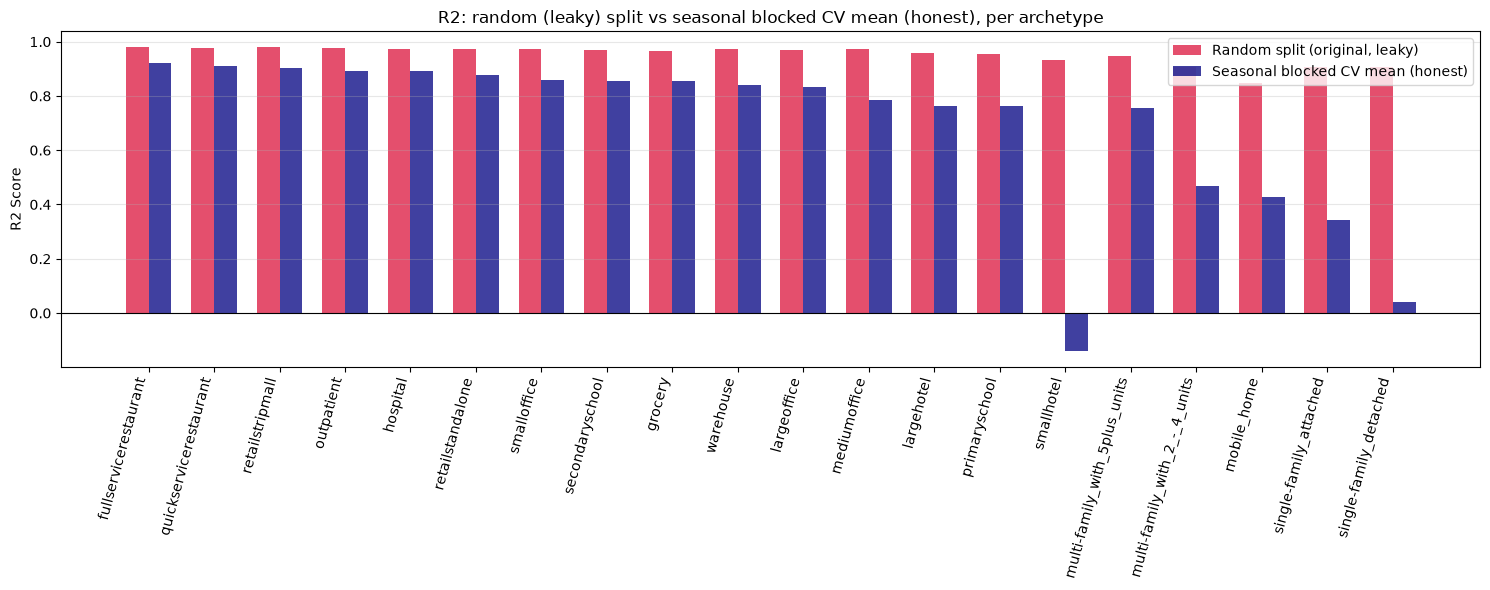

In [7]:
orig_res = pd.read_csv("metrics/training_metrics.csv")
orig_res["Building_Type"] = orig_res["Building_Type"].str.replace("up00-2a-", "", regex=False)
orig_com = pd.read_csv("metrics_comstock/comstock_training_metrics.csv")

orig_all = pd.concat([
    orig_res[["Building_Type", "R2_Score"]].rename(columns={"R2_Score": "R2_Random_Split"}),
    orig_com[["Building_Type", "R2_Score"]].rename(columns={"R2_Score": "R2_Random_Split"}),
])

seasonal_mean = seasonal_pivot[["mean"]].reset_index().rename(columns={"mean": "R2_Seasonal_CV_Mean"})

compare_all = orig_all.merge(seasonal_mean, on="Building_Type").merge(diagnostic_df, on="Building_Type")
compare_all["Sector"] = compare_all["Building_Type"].apply(lambda b: "Residential" if b in res_building_types else "Commercial")
compare_all["Drop_vs_Random"] = compare_all["R2_Random_Split"] - compare_all["R2_Seasonal_CV_Mean"]
compare_all = compare_all.sort_values(["Sector", "R2_Seasonal_CV_Mean"], ascending=[True, False])

print(compare_all[["Building_Type", "Sector", "R2_Random_Split", "R2_Seasonal_CV_Mean", "Drop_vs_Random"]].to_string(index=False))
print()
for sector in ["Residential", "Commercial"]:
    sub = compare_all[compare_all["Sector"] == sector]
    print(f"{sector}: mean R2 random={sub['R2_Random_Split'].mean():.4f}  "
          f"mean R2 seasonal-CV={sub['R2_Seasonal_CV_Mean'].mean():.4f}  "
          f"mean drop={sub['Drop_vs_Random'].mean():.4f}")

fig, ax = plt.subplots(figsize=(15, 6))
idx = np.arange(len(compare_all))
width = 0.35
colors = ["darkorange" if s == "Residential" else "teal" for s in compare_all["Sector"]]
ax.bar(idx - width/2, compare_all["R2_Random_Split"], width, label="Random split (original, leaky)", color="crimson", alpha=0.75)
ax.bar(idx + width/2, compare_all["R2_Seasonal_CV_Mean"], width, label="Seasonal blocked CV mean (honest)", color="navy", alpha=0.75)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(idx)
ax.set_xticklabels(compare_all["Building_Type"], rotation=75, ha="right")
ax.set_ylabel("R2 Score")
ax.set_title("R2: random (leaky) split vs seasonal blocked CV mean (honest), per archetype")
ax.legend()
ax.grid(True, alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


#### Train final production models on the full year (cyclical features)

Standard practice: cross-validation above already estimated honest generalization performance, so the deployed model that generates the bus-level 8760h profiles is trained on all 8760 hours (not a held-out 80%), to use all available data.

In [8]:
models_temporal_res_dir = Path("models_temporal/residential")
models_temporal_res_dir.mkdir(parents=True, exist_ok=True)
models_temporal_com_dir = Path("models_temporal/commercial")
models_temporal_com_dir.mkdir(parents=True, exist_ok=True)

print("Training FINAL production models on the full year (cyclical features)...")

final_metrics = []
for b_type, (df_hourly, target_col) in all_profiles.items():
    y = df_hourly[target_col].values
    rf = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
    rf.fit(X_cyc, y)

    if b_type in hourly_profiles_res:
        safe_name = b_type.replace(" ", "_").replace("/", "-")
        model_path = models_temporal_res_dir / f"rf_model_{safe_name}.joblib"
    else:
        model_path = models_temporal_com_dir / f"rf_model_{b_type}.joblib"

    joblib.dump(rf, model_path)
    final_metrics.append({"Building_Type": b_type, "Model_Path": str(model_path), "Train_Size": len(X_cyc)})
    print(f" -> saved {model_path}")

final_metrics_df = pd.DataFrame(final_metrics)
final_metrics_df.to_csv(metrics_temporal_dir / "final_production_models.csv", index=False)
print(f"\n{len(final_metrics_df)} models saved. Expected honest performance = seasonal CV mean above.")


Training FINAL production models on the full year (cyclical features)...
 -> saved models_temporal/residential/rf_model_mobile_home.joblib
 -> saved models_temporal/residential/rf_model_single-family_detached.joblib
 -> saved models_temporal/residential/rf_model_single-family_attached.joblib
 -> saved models_temporal/residential/rf_model_multi-family_with_2_-_4_units.joblib
 -> saved models_temporal/residential/rf_model_multi-family_with_5plus_units.joblib
 -> saved models_temporal/commercial/rf_model_fullservicerestaurant.joblib
 -> saved models_temporal/commercial/rf_model_grocery.joblib
 -> saved models_temporal/commercial/rf_model_hospital.joblib
 -> saved models_temporal/commercial/rf_model_largehotel.joblib
 -> saved models_temporal/commercial/rf_model_largeoffice.joblib
 -> saved models_temporal/commercial/rf_model_mediumoffice.joblib
 -> saved models_temporal/commercial/rf_model_outpatient.joblib
 -> saved models_temporal/commercial/rf_model_primaryschool.joblib
 -> saved model

#### Regenerate bus-level 8760h profiles with the final production models

In [9]:
final_bus_counts = pd.read_csv(exports / "final_bus_building_counts.csv")
final_bus_counts["Bus_Number"] = final_bus_counts["Bus_Number"].astype(str)

base_profiles_temporal_res = {}
for b_type in res_building_types:
    safe_name = b_type.replace(" ", "_").replace("/", "-")
    model = joblib.load(models_temporal_res_dir / f"rf_model_{safe_name}.joblib")
    base_profiles_temporal_res[b_type] = model.predict(X_cyc)

base_profiles_temporal_res_df = pd.DataFrame(base_profiles_temporal_res, index=weather_clean["date_time"])

counts_matrix_res = final_bus_counts.set_index("Bus_Number")[base_profiles_temporal_res_df.columns].fillna(0)
bus_profiles_temporal_res_df = base_profiles_temporal_res_df.dot(counts_matrix_res.T)

out_path_res = exports / "final_bus_load_profiles_8760_temporal.csv"
bus_profiles_temporal_res_df.to_csv(out_path_res)
print(f"Residential temporal bus profiles: {bus_profiles_temporal_res_df.shape} -> {out_path_res}")


Residential temporal bus profiles: (8760, 200) -> loadcurves/exports/final_bus_load_profiles_8760_temporal.csv


In [10]:
bus_sqft_matrix = pd.read_csv(exports / "bus_commercial_sqft.csv", index_col=0)
bus_sqft_matrix.index = bus_sqft_matrix.index.astype(str)

base_profiles_temporal_com = {}
for b_type in com_building_types:
    model = joblib.load(models_temporal_com_dir / f"rf_model_{b_type}.joblib")
    base_profiles_temporal_com[b_type] = model.predict(X_cyc)

base_profiles_temporal_com_df = pd.DataFrame(base_profiles_temporal_com, index=weather_clean["date_time"])

counts_matrix_com = bus_sqft_matrix[base_profiles_temporal_com_df.columns].fillna(0)
bus_profiles_temporal_com_df = base_profiles_temporal_com_df.dot(counts_matrix_com.T)

out_path_com = exports / "final_comstock_bus_load_profiles_8760_temporal.csv"
bus_profiles_temporal_com_df.to_csv(out_path_com)
print(f"Commercial temporal bus profiles: {bus_profiles_temporal_com_df.shape} -> {out_path_com}")


Commercial temporal bus profiles: (8760, 200) -> loadcurves/exports/final_comstock_bus_load_profiles_8760_temporal.csv


#### Does the fix change the headline validation number?

Same ERCOT parsing (DST-aware, `Etc/GMT+5`) and same calibration scales (`IND=4500 MW`, `RES_SCALE=1.9`, `COM_SCALE=1.3`, the paper's grid-search optimum) as `plot_all.ipynb`, applied to both the original (leaky-trained) and the new (full-year, cyclically-featured) bus-level profiles.

In [11]:
file_path = exports / "Native_Load_2018.xlsx"
ercot_df = pd.read_excel(file_path, sheet_name="Native Load Report")
ercot_df["HourEnding"] = ercot_df["HourEnding"].astype(str)

is_dst_mask = ercot_df["HourEnding"].str.contains(" DST", regex=False)
ercot_df["HourEnding"] = ercot_df["HourEnding"].str.replace(" DST", "", regex=False)
mask_24 = ercot_df["HourEnding"].str.contains("24:00")
ercot_df["HourEnding"] = ercot_df["HourEnding"].str.replace("24:00", "00:00")

naive_timestamps = pd.to_datetime(ercot_df["HourEnding"])
naive_timestamps.loc[mask_24] += pd.Timedelta(days=1)

ercot_df["date_time"] = naive_timestamps.dt.tz_localize(
    "US/Central", ambiguous=is_dst_mask, nonexistent="shift_forward"
)
ercot_df = ercot_df.set_index("date_time")
ercot_df_est = ercot_df.tz_convert("Etc/GMT+5")

ercot_plot_data = ercot_df_est["COAST"].copy()
ercot_plot_data.index = ercot_plot_data.index.tz_localize(None)

IND_BASE_MW, RES_SCALE, COM_SCALE = 4500.0, 1.9, 1.3


def stack_and_correlate(res_path, com_path, label):
    res_df = pd.read_csv(res_path, index_col=0, parse_dates=True)
    com_df = pd.read_csv(com_path, index_col=0, parse_dates=True)
    total_res_mw = (res_df.sum(axis=1) / 1000) * RES_SCALE
    total_com_mw = (com_df.sum(axis=1) / 1000) * COM_SCALE

    common_start = max(ercot_plot_data.index.min(), total_res_mw.index.min())
    common_end = min(ercot_plot_data.index.max(), total_res_mw.index.max())

    y_actual = ercot_plot_data.loc[common_start:common_end]
    y_ind = pd.Series(IND_BASE_MW, index=y_actual.index)
    y_total = y_ind + total_res_mw.loc[common_start:common_end] + total_com_mw.loc[common_start:common_end]

    corr = y_actual.corr(y_total)
    print(f"{label:12s} Pearson vs ERCOT Coast (calibrated stack): {corr:.4f}  |  peak={y_total.max():,.0f} MW")
    return corr


print("=== Headline validation: original (leaky-trained) vs temporal (honest CV, full-year-trained) models ===")
corr_original = stack_and_correlate(
    exports / "final_bus_load_profiles_8760.csv",
    exports / "final_comstock_bus_load_profiles_8760.csv",
    "Original",
)
corr_temporal = stack_and_correlate(
    exports / "final_bus_load_profiles_8760_temporal.csv",
    exports / "final_comstock_bus_load_profiles_8760_temporal.csv",
    "Temporal",
)
print(f"\nDelta (temporal - original): {corr_temporal - corr_original:+.4f}")


=== Headline validation: original (leaky-trained) vs temporal (honest CV, full-year-trained) models ===
Original     Pearson vs ERCOT Coast (calibrated stack): 0.8819  |  peak=24,418 MW
Temporal     Pearson vs ERCOT Coast (calibrated stack): 0.8907  |  peak=24,604 MW

Delta (temporal - original): +0.0089


#### Summary

- A single chronological 80/20 holdout is not, by itself, a trustworthy evaluation on one year of hourly data: the test tail is the only sample of late-autumn/winter behavior in the whole dataset, and cyclical calendar encoding does not reliably fix that (it helps some archetypes, hurts others) — the real fix is the evaluation protocol.
- Blocked seasonal 4-fold CV is used instead: train on 3 seasons, test on the 4th, rotate. It shows the original random-split R2 was optimistic for every archetype, but the honest gap is very different by sector: **commercial holds up reasonably well** (seasonal-CV mean R2 mostly 0.6-0.95), while **residential drops much further**, especially in winter/spring (some archetypes near 0 or negative). This is plausibly because ResStock's electricity-only target mixes homes with electric heat and homes with gas heat, and the available features can't distinguish them, whereas commercial loads are more schedule-driven and homogeneous year-round.
- Final production models (used for the bus-level profiles below) are trained on the full year, since the CV above already estimated their honest generalization error.
- The final ERCOT correlation comparison shows whether fixing the leakage changes the paper's headline system-level validation conclusion.
- For review point 6 (RF vs XGBoost/LightGBM): any such comparison should be run through the same seasonal blocked CV, not the original random split — and the residential winter/spring weakness found here is a good candidate to test whether a different model or additional features (e.g. a heating-fuel-mix proxy) closes the gap.